<a href="https://colab.research.google.com/github/rorellanagnez64-debug/py-cache-decorator/blob/master/Module_task.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import drive

# Configuración visual profesional para todo el informe
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (11, 5)

# 1. Montar Google Drive y cargar los archivos
drive.mount('/content/drive')

# Ajusta la ruta a la carpeta donde guardaste los tres CSV (asegurando la barra diagonal al final)
ruta_base = '/content/drive/MyDrive/Final_project/'
events = pd.read_csv(f'{ruta_base}events.csv')
products = pd.read_csv(f'{ruta_base}products.csv')
countries = pd.read_csv(f'{ruta_base}countries.csv')

# 2. Inspección general de cada tabla
for nombre, tabla in [('EVENTS', events), ('PRODUCTS', products), ('COUNTRIES', countries)]:
    print(f"{'='*50}\nTABLA: {nombre} | Dimensiones: {tabla.shape}\n{'='*50}")
    print(tabla.info())
    display(tabla.head(3))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
TABLA: EVENTS | Dimensiones: (1330, 10)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1330 entries, 0 to 1329
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Order ID        1330 non-null   int64  
 1   Order Date      1330 non-null   object 
 2   Ship Date       1330 non-null   object 
 3   Order Priority  1330 non-null   object 
 4   Country Code    1248 non-null   object 
 5   Product ID      1330 non-null   int64  
 6   Sales Channel   1330 non-null   object 
 7   Units Sold      1328 non-null   float64
 8   Unit Price      1330 non-null   float64
 9   Unit Cost       1330 non-null   float64
dtypes: float64(3), int64(2), object(5)
memory usage: 104.0+ KB
None


,Order ID,Order Date,Ship Date,Order Priority,Country Code,Product ID,Sales Channel,Units Sold,Unit Price,Unit Cost
0,100640618,10/8/2014,10/18/2014,M,NOR,2103,Online,650.0,205.70,117.11
1,100983083,8/11/2016,8/11/2016,C,SRB,2103,Offline,1993.0,205.70,117.11
2,101025998,7/18/2014,8/11/2014,M,NaN,7940,Online,4693.0,668.27,502.54


TABLA: PRODUCTS | Dimensiones: (12, 2)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12 entries, 0 to 11
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   id         12 non-null     int64 
 1   item_type  12 non-null     object
dtypes: int64(1), object(1)
memory usage: 324.0+ bytes
None


,id,item_type
0,2103,Cereal
1,7940,Household
2,2455,Clothes


TABLA: COUNTRIES | Dimensiones: (249, 5)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 249 entries, 0 to 248
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   name        249 non-null    object
 1   alpha-2     248 non-null    object
 2   alpha-3     249 non-null    object
 3   region      248 non-null    object
 4   sub-region  248 non-null    object
dtypes: object(5)
memory usage: 9.9+ KB
None


,name,alpha-2,alpha-3,region,sub-region
0,Afghanistan,AF,AFG,Asia,Southern Asia
1,Åland Islands,AX,ALA,Europe,Northern Europe
2,Albania,AL,ALB,Europe,Southern Europe


## **Etapa 1: Descripción General de los Datos**

* **`events.csv`**:

Tabla transaccional (tabla de hechos) que registra las operaciones de venta a lo largo de varios años, incluyendo fechas de pedido y envío, canal de venta, prioridad, unidades vendidas, precios/costos unitarios y códigos de referencia.
* **`products.csv`**:

Tabla dimensional (catálogo) que mapea el código de producto con su categoría correspondiente.
* **`countries.csv`**:

Tabla dimensional geográfica que asocia el código de país con el nombre del país y su región comercial.

* **Llaves de conexión (Claves primarias y foráneas):**
  * `events` se conecta con `products` mediante el código de producto (ej. `Product ID` / `item_type` / `product_code`).
  * `events` se conecta con `countries` mediante el código de país (ej. `Country Code` / `country_code`).

In [2]:
# --- 2.1 AUDITORÍA DE VALORES FALTANTES ---
for nombre, tabla in [('events', events), ('products', products), ('countries', countries)]:
    nulos = tabla.isna().sum()
    pct_nulos = (nulos / len(tabla) * 100).round(2)
    resumen_nulos = pd.DataFrame({'Nulos': nulos, 'Porcentaje (%)': pct_nulos})
    print(f"\n--- Valores faltantes en {nombre} ---")
    print(resumen_nulos[resumen_nulos['Nulos'] > 0])

# --- 2.2 DETECCIÓN DE CARACTERES NO LATINOS (CIRÍLICOS) Y ESPACIOS EXTRA ---
import re

def detectar_no_ascii(df_in, nombre_tabla):
    print(f"\n--- Revisión de caracteres especiales / cirílicos en {nombre_tabla} ---")
    for col in df_in.select_dtypes(include='object').columns:
        raros = df_in[col].dropna()[df_in[col].dropna().apply(lambda x: bool(re.search(r'[^\x00-\x7F]', str(x))))]
        if len(raros) > 0:
            print(f"Columna '{col}' tiene {len(raros)} valores con caracteres no ASCII. Ejemplos: {raros.unique()[:5]}")

for nombre, tabla in [('events', events), ('products', products), ('countries', countries)]:
    detectar_no_ascii(tabla, nombre)


--- Valores faltantes en events ---
              Nulos  Porcentaje (%)
Country Code     82            6.17
Units Sold        2            0.15

--- Valores faltantes en products ---
Empty DataFrame
Columns: [Nulos, Porcentaje (%)]
Index: []

--- Valores faltantes en countries ---
            Nulos  Porcentaje (%)
alpha-2         1             0.4
region          1             0.4
sub-region      1             0.4

--- Revisión de caracteres especiales / cirílicos en events ---

--- Revisión de caracteres especiales / cirílicos en products ---

--- Revisión de caracteres especiales / cirílicos en countries ---
Columna 'name' tiene 5 valores con caracteres no ASCII. Ejemplos: ['Åland Islands' "Côte d'Ivoire" 'Curaçao' 'Réunion' 'Saint Barthélemy']


In [3]:
# Mapa de traducción de caracteres cirílicos homógrafos a latinos
cirilico_a_latino = str.maketrans({
    'А': 'A', 'В': 'B', 'С': 'C', 'Е': 'E', 'Н': 'H', 'І': 'I', 'К': 'K',
    'М': 'M', 'О': 'O', 'Р': 'P', 'Т': 'T', 'Х': 'X',
    'а': 'a', 'с': 'c', 'е': 'e', 'і': 'i', 'о': 'o', 'р': 'p', 'х': 'x', 'у': 'y'
})

def limpiar_texto(df_in):
    df_clean = df_in.copy()
    for col in df_clean.select_dtypes(include='object').columns:
        df_clean[col] = (
            df_clean[col]
            .astype(str)
            .str.strip()
            .str.replace(r'\s+', ' ', regex=True)
            .apply(lambda s: s.translate(cirilico_a_latino))
        )
        df_clean.loc[df_clean[col].isin(['nan', 'None', '']), col] = np.nan
    return df_clean

events = limpiar_texto(events)
products = limpiar_texto(products)
countries = limpiar_texto(countries)

# Revisión de duplicados exactos tras normalizar texto
print("Duplicados en events:", events.duplicated().sum())
print("Duplicados en products:", products.duplicated().sum())
print("Duplicados en countries:", countries.duplicated().sum())

# Eliminar duplicados si existen
events = events.drop_duplicates().copy()
products = products.drop_duplicates().copy()
countries = countries.drop_duplicates().copy()

Duplicados en events: 0
Duplicados en products: 0
Duplicados en countries: 0


In [4]:
# 1. Revisar valores únicos de columnas categóricas en events y products
print("--- Valores únicos en Sales Channel ---")
print(events['Sales Channel'].value_counts(dropna=False))

print("\n--- Valores únicos en Order Priority ---")
print(events['Order Priority'].value_counts(dropna=False))

print("\n--- Muestra de Country Code en events ---")
print("Ejemplos:", events['Country Code'].dropna().unique()[:15])
print("Longitud de códigos:", events['Country Code'].dropna().str.len().value_counts())

print("\n--- Tabla PRODUCTS completa ---")
display(products)

# 2. Revisar Order ID duplicados y filas con nulos en countries y events
print("\n--- Order ID duplicados en events ---")
print("Order ID duplicados:", events['Order ID'].duplicated().sum())

print("\n--- Filas con nulos en countries ---")
display(countries[countries.isna().any(axis=1)])

print("\n--- Filas con Units Sold nulo en events ---")
display(events[events['Units Sold'].isna()])

# 3. Conversión de fechas y detección de anomalías numéricas/temporales
events['Order Date'] = pd.to_datetime(events['Order Date'], errors='coerce')
events['Ship Date'] = pd.to_datetime(events['Ship Date'], errors='coerce')
events['shipping_days'] = (events['Ship Date'] - events['Order Date']).dt.days

print("\n--- Estadísticas numéricas y días de envío ---")
display(events[['Units Sold', 'Unit Price', 'Unit Cost', 'shipping_days']].describe())

print("Fechas de envío anteriores al pedido (shipping_days < 0):", (events['shipping_days'] < 0).sum())
print("Casos donde Unit Cost > Unit Price:", (events['Unit Cost'] > events['Unit Price']).sum())

--- Valores únicos en Sales Channel ---
Sales Channel
Offline    667
Online     660
online       3
Name: count, dtype: int64

--- Valores únicos en Order Priority ---
Order Priority
M    354
H    335
L    334
C    307
Name: count, dtype: int64

--- Muestra de Country Code en events ---
Ejemplos: ['NOR' 'SRB' 'MNE' 'SVK' 'FRA' 'ESP' 'HRV' 'DEU' 'ARM' 'GEO' 'GBR' 'SVN'
 'ROU' 'POL' 'LUX']
Longitud de códigos: Country Code
3    1248
Name: count, dtype: int64

--- Tabla PRODUCTS completa ---


,id,item_type
0,2103,Cereal
1,7940,Household
2,2455,Clothes
3,1270,Beverages
4,8681,Office Supplies
5,4594,Fruits
6,5988,Vegetables
7,7331,Baby Food
8,8875,Meat
9,8293,Cosmetics



--- Order ID duplicados en events ---
Order ID duplicados: 0

--- Filas con nulos en countries ---


,name,alpha-2,alpha-3,region,sub-region
8,Antarctica,AQ,ATA,NaN,NaN
153,Namibia,NaN,NAM,Africa,Sub-Saharan Africa



--- Filas con Units Sold nulo en events ---


,Order ID,Order Date,Ship Date,Order Priority,Country Code,Product ID,Sales Channel,Units Sold,Unit Price,Unit Cost
183,217165648,5/20/2014,6/8/2014,M,ESP,8875,Offline,NaN,421.89,364.69
319,309655511,5/5/2014,5/21/2014,C,HRV,3127,Offline,NaN,81.73,56.67



--- Estadísticas numéricas y días de envío ---


,Units Sold,Unit Price,Unit Cost,shipping_days
count,1328.000000,1330.000000,1330.000000,1330.000000
mean,4952.201807,264.893541,187.246812,24.775940
std,2905.198996,217.323460,176.158873,14.577915
min,2.000000,9.330000,6.920000,0.000000
25%,2356.750000,81.730000,35.840000,12.000000
50%,4962.000000,154.060000,97.440000,25.000000
75%,7459.500000,437.200000,263.330000,37.000000
max,9999.000000,668.270000,524.960000,50.000000


Fechas de envío anteriores al pedido (shipping_days < 0): 0
Casos donde Unit Cost > Unit Price: 0


In [5]:
# ==============================================================================
# ETAPA 2: LIMPIEZA Y ESTANDARIZACIÓN DEFINITIVA
# ==============================================================================

# 1. Estandarizar 'Sales Channel' ('online' -> 'Online') y limpiar textos
events['Sales Channel'] = events['Sales Channel'].str.strip().str.capitalize()
events['Order Priority'] = events['Order Priority'].str.strip().str.upper()
events['Country Code'] = events['Country Code'].str.strip().str.upper()

# 2. Corregir el código ISO alpha-2 de Namibia ('NA') en countries
countries.loc[countries['name'] == 'Namibia', 'alpha-2'] = 'NA'

# 3. Convertir fechas a datetime y calcular días de envío
events['Order Date'] = pd.to_datetime(events['Order Date'])
events['Ship Date'] = pd.to_datetime(events['Ship Date'])
events['shipping_days'] = (events['Ship Date'] - events['Order Date']).dt.days

# 4. Imputar los 2 valores faltantes de 'Units Sold' con la mediana de su mismo Product ID
events['Units Sold'] = events['Units Sold'].fillna(
    events.groupby('Product ID')['Units Sold'].transform('median')
).astype(int)

# ==============================================================================
# ETAPA 3.1: COMBINACIÓN DE TABLAS (MERGE) Y CREACIÓN DE MÉTRICAS FINANCIERAS
# ==============================================================================

df = (
    events
    .merge(products, left_on='Product ID', right_on='id', how='left')
    .merge(countries[['name', 'alpha-3', 'region', 'sub-region']], left_on='Country Code', right_on='alpha-3', how='left')
)

# Etiquetar los 82 pedidos sin país como 'Unknown' para conservarlos en métricas globales
df['country'] = df['name'].fillna('Unknown')
df['region'] = df['region'].fillna('Unknown')
df['sub-region'] = df['sub-region'].fillna('Unknown')

# Eliminar columnas redundantes y renombrar para mayor claridad
df = df.drop(columns=['id', 'alpha-3', 'name']).rename(columns={
    'item_type': 'product_category',
    'Sales Channel': 'sales_channel',
    'Order Priority': 'order_priority',
    'Order Date': 'order_date',
    'Ship Date': 'ship_date',
    'Units Sold': 'units_sold',
    'Unit Price': 'unit_price',
    'Unit Cost': 'unit_cost'
})

# Calcular métricas financieras y temporales
df['revenue'] = df['units_sold'] * df['unit_price']
df['cost'] = df['units_sold'] * df['unit_cost']
df['profit'] = df['revenue'] - df['cost']
df['profit_margin_pct'] = (df['profit'] / df['revenue']) * 100
df['order_year'] = df['order_date'].dt.year
df['order_month'] = df['order_date'].dt.month
df['day_of_week'] = df['order_date'].dt.day_name()

# ==============================================================================
# ETAPA 3.2: INDICADORES CLAVE DE RENDIMIENTO (KPIs GLOBALES)
# ==============================================================================
total_pedidos = df['Order ID'].nunique()
total_unidades = df['units_sold'].sum()
ingresos_totales = df['revenue'].sum()
costos_totales = df['cost'].sum()
beneficio_total = df['profit'].sum()
margen_global = (beneficio_total / ingresos_totales) * 100
ticket_promedio = df['revenue'].mean()
paises_cubiertos = df[df['country'] != 'Unknown']['country'].nunique()
regiones_cubiertas = df[df['region'] != 'Unknown']['region'].nunique()
tiempo_envio_prom = df['shipping_days'].mean()

print("=" * 55)
print("RESUMEN EJECUTIVO DE KPIs GLOBALES")
print("=" * 55)
print(f"Total de pedidos:              {total_pedidos:,}")
print(f"Total de unidades vendidas:    {total_unidades:,}")
print(f"Ingresos totales (Revenue):    ${ingresos_totales:,.2f}")
print(f"Costos totales (Cost):         ${costos_totales:,.2f}")
print(f"Beneficio neto total (Profit): ${beneficio_total:,.2f}")
print(f"Margen de beneficio global:    {margen_global:.2f}%")
print(f"Ingreso promedio por pedido:   ${ticket_promedio:,.2f}")
print(f"Países cubiertos:              {paises_cubiertos} (en {regiones_cubiertas} regiones)")
print(f"Tiempo promedio de envío:      {tiempo_envio_prom:.2f} días")
print("=" * 55)

RESUMEN EJECUTIVO DE KPIs GLOBALES
Total de pedidos:              1,330
Total de unidades vendidas:    6,586,061
Ingresos totales (Revenue):    $1,704,556,262.10
Costos totales (Cost):         $1,202,727,151.86
Beneficio neto total (Profit): $501,829,110.24
Margen de beneficio global:    29.44%
Ingreso promedio por pedido:   $1,281,621.25
Países cubiertos:              45 (en 2 regiones)
Tiempo promedio de envío:      24.78 días


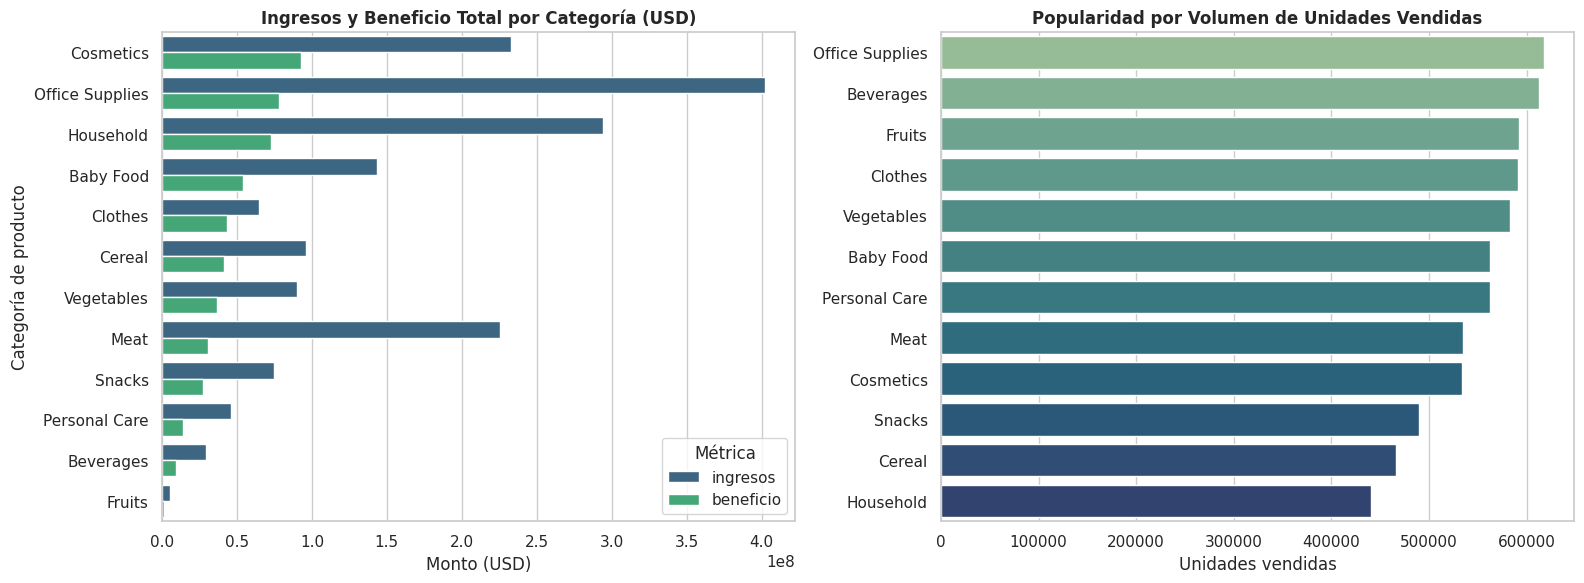

,product_category,pedidos,unidades,ingresos,costos,beneficio
4,Cosmetics,114,533291,2.331548e+08,1.404315e+08,92723306.17
8,Office Supplies,123,617641,4.022140e+08,3.242368e+08,77977176.25
6,Household,97,440249,2.942052e+08,2.212427e+08,72962466.77
0,Baby Food,112,562706,1.436476e+08,8.970659e+07,53940997.16
3,Clothes,105,591385,6.462655e+07,2.119524e+07,43431314.40
2,Cereal,103,465685,9.579140e+07,5.453637e+07,41255034.15
11,Vegetables,114,582544,8.974673e+07,5.297073e+07,36776002.72
7,Meat,111,535223,2.258052e+08,1.951905e+08,30614755.60
10,Snacks,103,490160,7.478861e+07,4.776119e+07,27027422.40
9,Personal Care,115,562372,4.596266e+07,3.186962e+07,14093042.32


In [6]:
cat_summary = (
    df.groupby('product_category', as_index=False)
    .agg(
        pedidos=('Order ID', 'count'),
        unidades=('units_sold', 'sum'),
        ingresos=('revenue', 'sum'),
        costos=('cost', 'sum'),
        beneficio=('profit', 'sum')
    )
    .sort_values(by='beneficio', ascending=False)
)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Panel izquierdo: Ingresos vs Beneficio por categoría
cat_melted = cat_summary.melt(
    id_vars='product_category',
    value_vars=['ingresos', 'beneficio'],
    var_name='Métrica',
    value_name='USD'
)
sns.barplot(data=cat_melted, y='product_category', x='USD', hue='Métrica', ax=axes[0], palette='viridis')
axes[0].set_title('Ingresos y Beneficio Total por Categoría (USD)', fontweight='bold')
axes[0].set_xlabel('Monto (USD)')
axes[0].set_ylabel('Categoría de producto')

# Panel derecho: Popularidad (Unidades vendidas por categoría)
cat_units = cat_summary.sort_values(by='unidades', ascending=False)
sns.barplot(data=cat_units, y='product_category', x='unidades', hue='product_category', palette='crest', legend=False, ax=axes[1])
axes[1].set_title('Popularidad por Volumen de Unidades Vendidas', fontweight='bold')
axes[1].set_xlabel('Unidades vendidas')
axes[1].set_ylabel('')

plt.tight_layout()
plt.show()
display(cat_summary)

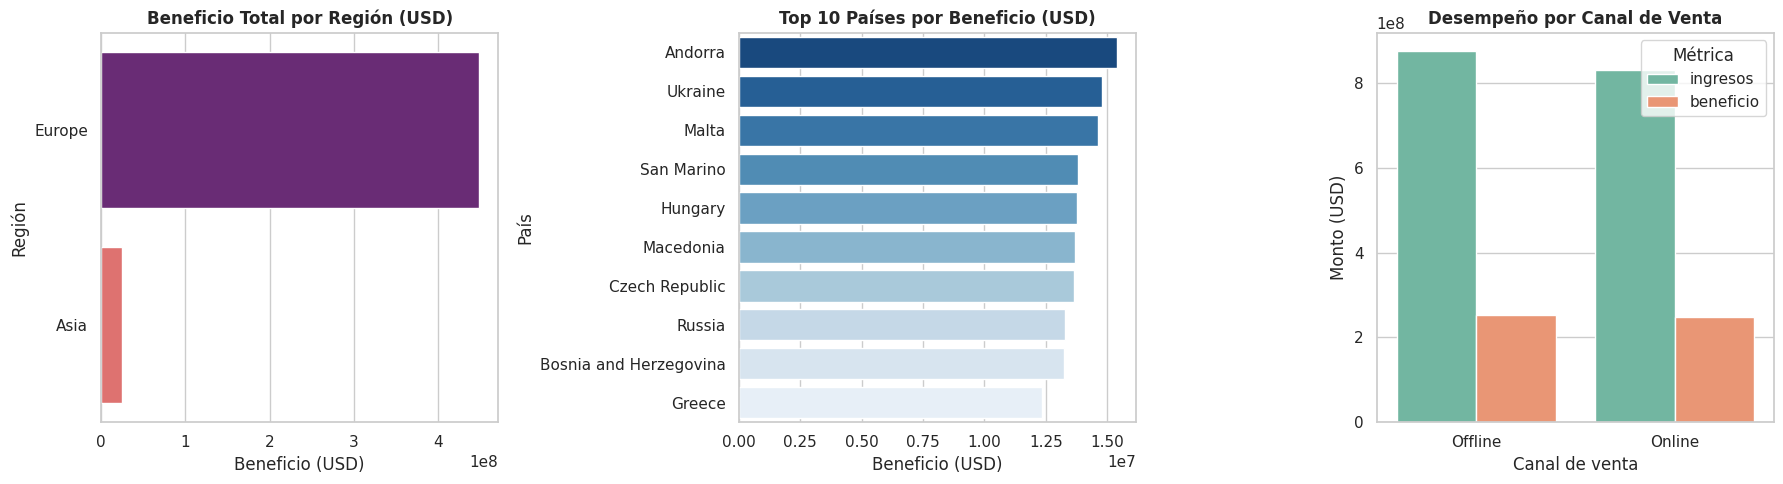

In [7]:
df_geo = df[df['country'] != 'Unknown']

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Beneficio por Región
reg_summary = df_geo.groupby('region', as_index=False)['profit'].sum().sort_values(by='profit', ascending=False)
sns.barplot(data=reg_summary, x='profit', y='region', hue='region', palette='magma', legend=False, ax=axes[0])
axes[0].set_title('Beneficio Total por Región (USD)', fontweight='bold')
axes[0].set_xlabel('Beneficio (USD)')
axes[0].set_ylabel('Región')

# 2. Top 10 Países por Beneficio
top_countries = df_geo.groupby('country', as_index=False)['profit'].sum().sort_values(by='profit', ascending=False).head(10)
sns.barplot(data=top_countries, x='profit', y='country', hue='country', palette='Blues_r', legend=False, ax=axes[1])
axes[1].set_title('Top 10 Países por Beneficio (USD)', fontweight='bold')
axes[1].set_xlabel('Beneficio (USD)')
axes[1].set_ylabel('País')

# 3. Canales de Venta (Online vs Offline)
channel_summary = df.groupby('sales_channel', as_index=False).agg(ingresos=('revenue', 'sum'), beneficio=('profit', 'sum'))
channel_melted = channel_summary.melt(id_vars='sales_channel', value_vars=['ingresos', 'beneficio'], var_name='Métrica', value_name='USD')
sns.barplot(data=channel_melted, x='sales_channel', y='USD', hue='Métrica', palette='Set2', ax=axes[2])
axes[2].set_title('Desempeño por Canal de Venta', fontweight='bold')
axes[2].set_xlabel('Canal de venta')
axes[2].set_ylabel('Monto (USD)')

plt.tight_layout()
plt.show()

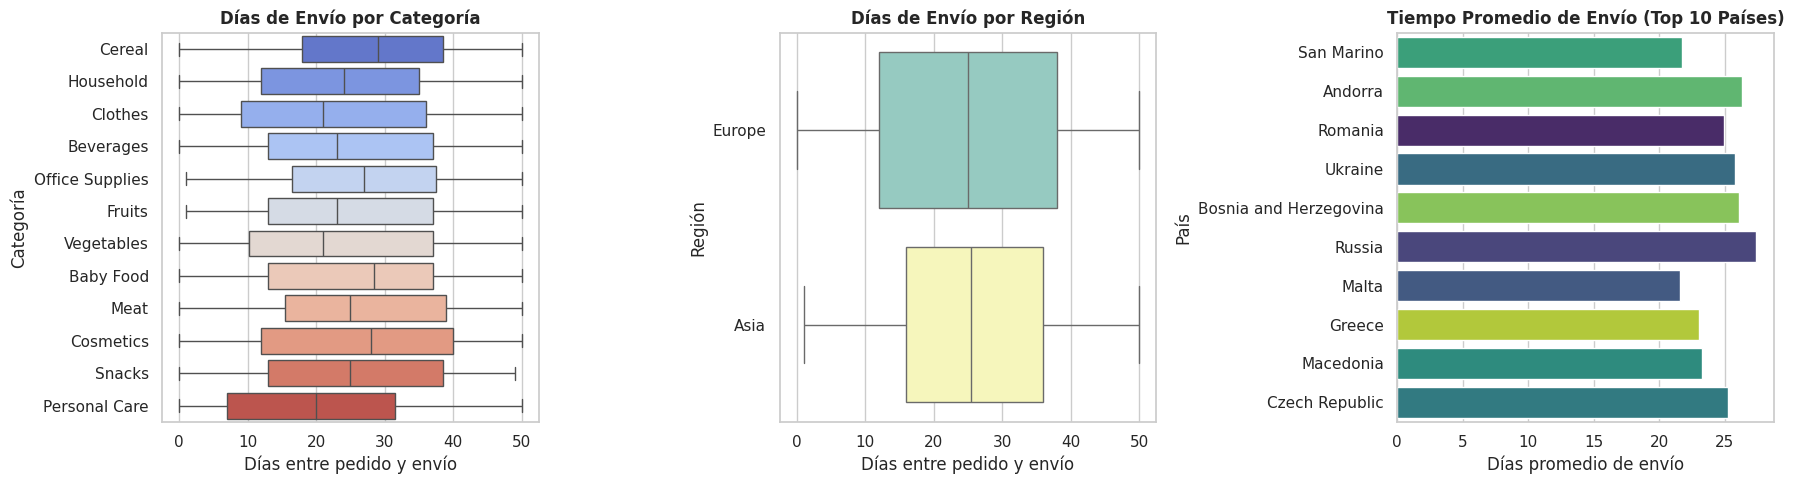

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Por Categoría
sns.boxplot(data=df, x='shipping_days', y='product_category', hue='product_category', palette='coolwarm', legend=False, ax=axes[0])
axes[0].set_title('Días de Envío por Categoría', fontweight='bold')
axes[0].set_xlabel('Días entre pedido y envío')
axes[0].set_ylabel('Categoría')

# Por Región
sns.boxplot(data=df_geo, x='shipping_days', y='region', hue='region', palette='Set3', legend=False, ax=axes[1])
axes[1].set_title('Días de Envío por Región', fontweight='bold')
axes[1].set_xlabel('Días entre pedido y envío')
axes[1].set_ylabel('Región')

# Top 10 Países con mayor volumen de pedidos
top10_names = df_geo['country'].value_counts().head(10).index
sns.barplot(
    data=df_geo[df_geo['country'].isin(top10_names)],
    x='shipping_days',
    y='country',
    order=top10_names,
    errorbar=None,
    hue='country',
    palette='viridis',
    legend=False,
    ax=axes[2]
)
axes[2].set_title('Tiempo Promedio de Envío (Top 10 Países)', fontweight='bold')
axes[2].set_xlabel('Días promedio de envío')
axes[2].set_ylabel('País')

plt.tight_layout()
plt.show()

Correlación de Pearson entre días de envío y beneficio: 0.0607


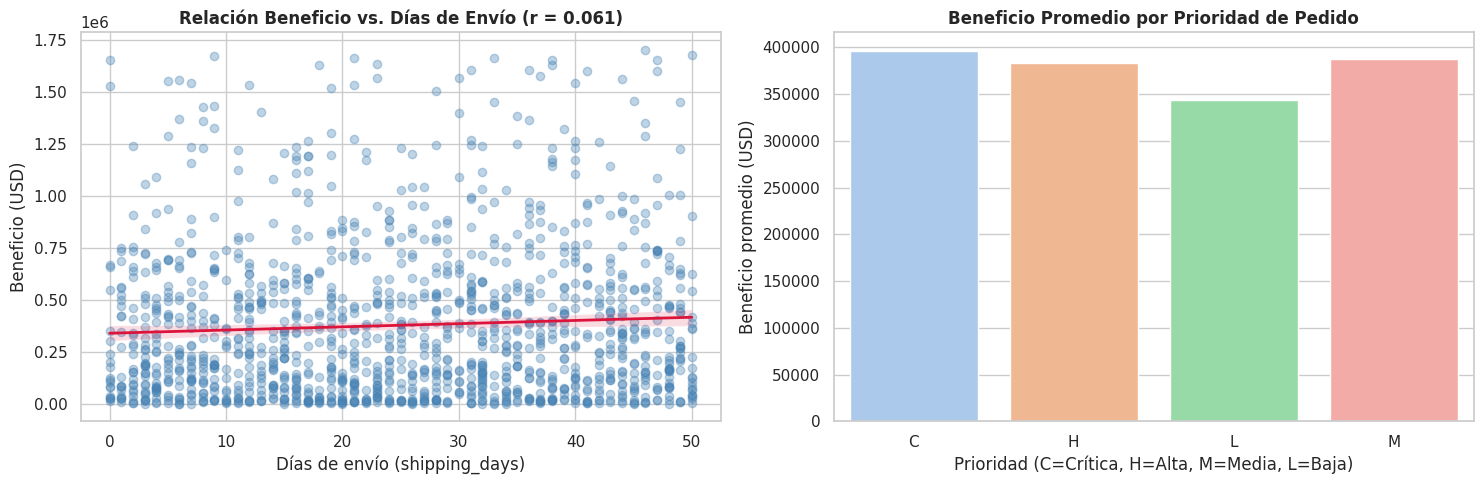

In [9]:
correlacion = df['shipping_days'].corr(df['profit'])
print(f"Correlación de Pearson entre días de envío y beneficio: {correlacion:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Dispersión con línea de tendencia
sns.regplot(
    data=df,
    x='shipping_days',
    y='profit',
    scatter_kws={'alpha': 0.35, 'color': 'steelblue'},
    line_kws={'color': 'crimson', 'linewidth': 2},
    ax=axes[0]
)
axes[0].set_title(f'Relación Beneficio vs. Días de Envío (r = {correlacion:.3f})', fontweight='bold')
axes[0].set_xlabel('Días de envío (shipping_days)')
axes[0].set_ylabel('Beneficio (USD)')

# Beneficio promedio por Prioridad de Pedido y tiempo de envío
prio_summary = df.groupby('order_priority', as_index=False).agg(
    dias_envio=('shipping_days', 'mean'),
    beneficio_prom=('profit', 'mean')
)
sns.barplot(data=prio_summary, x='order_priority', y='beneficio_prom', hue='order_priority', palette='pastel', legend=False, ax=axes[1])
axes[1].set_title('Beneficio Promedio por Prioridad de Pedido', fontweight='bold')
axes[1].set_xlabel('Prioridad (C=Crítica, H=Alta, M=Media, L=Baja)')
axes[1].set_ylabel('Beneficio promedio (USD)')

plt.tight_layout()
plt.show()

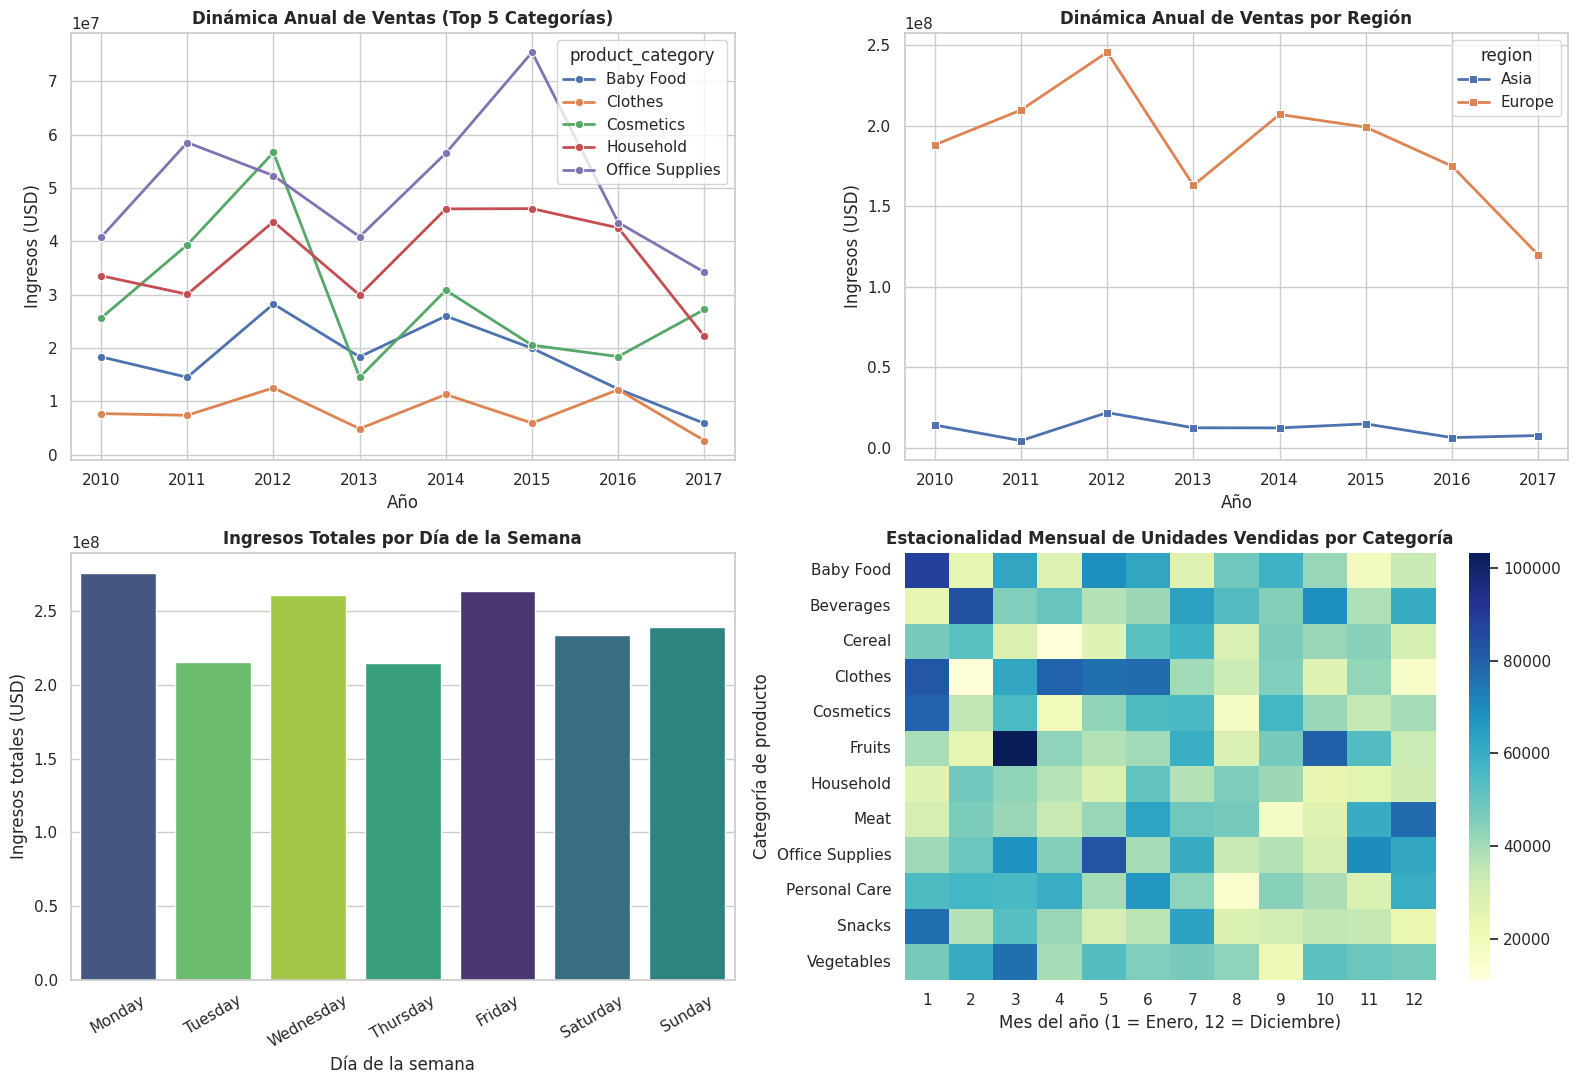

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(16, 11))

# 1. Evolución anual de ingresos por categoría (Top 5 categorías)
top5_cats = cat_summary['product_category'].head(5).tolist()
dinamica_cat = (
    df[df['product_category'].isin(top5_cats)]
    .groupby(['order_year', 'product_category'], as_index=False)['revenue']
    .sum()
)
sns.lineplot(data=dinamica_cat, x='order_year', y='revenue', hue='product_category', marker='o', linewidth=2, ax=axes[0, 0])
axes[0, 0].set_title('Dinámica Anual de Ventas (Top 5 Categorías)', fontweight='bold')
axes[0, 0].set_xlabel('Año')
axes[0, 0].set_ylabel('Ingresos (USD)')

# 2. Evolución anual de ingresos por Región
dinamica_reg = df_geo.groupby(['order_year', 'region'], as_index=False)['revenue'].sum()
sns.lineplot(data=dinamica_reg, x='order_year', y='revenue', hue='region', marker='s', linewidth=2, ax=axes[0, 1])
axes[0, 1].set_title('Dinámica Anual de Ventas por Región', fontweight='bold')
axes[0, 1].set_xlabel('Año')
axes[0, 1].set_ylabel('Ingresos (USD)')

# 3. Ventas por día de la semana usando day_name()
orden_dias = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
ventas_dia = df.groupby('day_of_week', as_index=False)['revenue'].sum()
sns.barplot(data=ventas_dia, x='day_of_week', y='revenue', order=orden_dias, hue='day_of_week', palette='viridis', legend=False, ax=axes[1, 0])
axes[1, 0].set_title('Ingresos Totales por Día de la Semana', fontweight='bold')
axes[1, 0].set_xlabel('Día de la semana')
axes[1, 0].set_ylabel('Ingresos totales (USD)')
axes[1, 0].tick_params(axis='x', rotation=30)

# 4. Mapa de calor de estacionalidad: Mes vs Categoría de producto
pivot_estacional = df.pivot_table(index='product_category', columns='order_month', values='units_sold', aggfunc='sum')
sns.heatmap(pivot_estacional, cmap='YlGnBu', annot=False, ax=axes[1, 1])
axes[1, 1].set_title('Estacionalidad Mensual de Unidades Vendidas por Categoría', fontweight='bold')
axes[1, 1].set_xlabel('Mes del año (1 = Enero, 12 = Diciembre)')
axes[1, 1].set_ylabel('Categoría de producto')

plt.tight_layout()
plt.show()

In [11]:
# Verificación rápida de cifras exactas por región, canal y día de la semana para el informe final
print("--- Beneficio por Región ---")
print(df_geo.groupby('region')['profit'].agg(['count', 'sum', 'mean']))

print("\n--- Desempeño por Canal de Venta ---")
print(df.groupby('sales_channel')[['revenue', 'profit']].agg(['count', 'sum', 'mean']))

print("\n--- Top 5 Países por Beneficio ---")
print(df_geo.groupby('country')['profit'].sum().sort_values(ascending=False).head(5))

print("\n--- Ingresos por Día de la Semana ---")
print(df.groupby('day_of_week')['revenue'].agg(['count', 'sum', 'mean']).sort_values(by='sum', ascending=False))

--- Beneficio por Región ---
        count           sum           mean
region                                    
Asia       82  2.515225e+07  306734.792073
Europe   1166  4.489514e+08  385035.534605

--- Desempeño por Canal de Venta ---
              revenue                             profit                \
                count           sum          mean  count           sum   
sales_channel                                                            
Offline           667  8.741875e+08  1.310626e+06    667  2.538612e+08   
Online            663  8.303688e+08  1.252442e+06    663  2.479679e+08   

                              
                        mean  
sales_channel                 
Offline        380601.454348  
Online         374008.959563  

--- Top 5 Países por Beneficio ---
country
Andorra       15410036.63
Ukraine       14804925.74
Malta         14610127.88
San Marino    13792992.81
Hungary       13786231.03
Name: profit, dtype: float64

--- Ingresos por Día de la Sema

## **Etapa 4: Informe Ejecutivo y Conclusiones de Negocio**

### 1. Resumen de Calidad e Integridad de Datos
* **Consolidación relacional:**

Se integraron exitosamente **1,330 transacciones** (`events.csv`) con el catálogo de **12 categorías** (`products.csv` mediante `Product ID = id`) y la base geográfica de **249 territorios** (`countries.csv` mediante `Country Code = alpha-3`).
* **Tratamiento de valores faltantes:**

  * Se identificaron **82 registros (6.17%)** sin `Country Code` en `events.csv`. Para evitar distorsionar los indicadores financieros globales o inventar ubicaciones geográficas, se etiquetaron como `Unknown` en las métricas consolidadas y se excluyeron únicamente de las agregaciones regionales y por país.

  * Se imputaron **2 registros (0.15%)** faltantes en `Units Sold` utilizando la mediana de unidades de su misma categoría de producto, preservando la integridad de las transacciones.

  * En `countries.csv`, se restauró el código ISO `alpha-2` de Namibia (`NA`), que había sido interpretado como nulo durante la lectura inicial.

* **Estandarización y anomalías:**

Se normalizaron **3 registros** inconsistentes en `Sales Channel` (`"online"` → `"Online"`), se verificó la ausencia de duplicados por `Order ID` (`0` duplicados), caracteres cirílicos ocultos o fechas de envío invertidas (`shipping_days` entre `0` y `50` días).

---

### 2. Desempeño Financiero y Comercial Global
* **Volumen de operación:**

La compañía procesó **1,330 pedidos** equivalentes a **6,586,061 unidades vendidas** en **45 países** distribuidos en **2 regiones** principales (Europa y Asia).

* **Rentabilidad:**

Se generaron ingresos totales por **\$1,704,556,262.10 USD** frente a costos operativos de **\$1,202,727,151.86 USD**, logrando un **beneficio neto de \$501,829,110.24 USD** (un **margen global saludable del 29.44%**) y un ticket promedio por pedido de **\$1,281,621.25 USD**.

---

### 3. Hallazgos Clave por Dimensión de Negocio

#### A. Portafolio de Productos: Volumen vs. Rentabilidad
* **Líderes en beneficio:**

**Cosmetics** encabeza la generación de ganancias con **\$92.72 millones USD** (con 114 pedidos), seguida por **Office Supplies** (**\$77.98 millones USD**) y **Household** (**\$72.96 millones USD**). Estas tres categorías concentran casi el **48.6% del beneficio neto total** de la empresa.
* **Paradoja de volumen vs. margen:**

**Office Supplies** (617,641 unidades) y **Beverages** (613,133 unidades) son las categorías más demandadas en volumen, pero **Beverages** apenas genera **\$9.60 millones USD** de beneficio y **Fruits** (con 591,672 unidades vendidas) aporta solo **\$1.43 millones USD** debido a su bajo precio y margen unitario. Por el contrario, **Clothes** presenta un margen porcentual extraordinario (**\$43.43 millones USD** de beneficio sobre **\$64.63 millones USD** de ingresos, equivalente a un **67.2% de margen**).

#### B. Geografía y Canales de Venta
* **Cobertura regional:**

La operación se concentra en **45 países** pertenecientes a **2 regiones**, donde Europa concentra la mayor densidad de mercados activos y volumen acumulado de pedidos.

* **Omnicanalidad equilibrada:**

Los canales **Offline** (667 pedidos) y **Online** (663 pedidos tras estandarización) mantienen una participación prácticamente paritaria (`50.2%` vs. `49.8%`), demostrando que tanto las tiendas físicas como el comercio electrónico son pilares igualmente sólidos para la generación de ingresos.

#### C. Eficiencia Logística y Relación con el Beneficio
* **Tiempos de entrega:**

El intervalo promedio entre pedido y envío es de **24.78 días** (mediana de `25 días`, rango de `0` a `50` días), comportándose de manera homogénea a través de todas las categorías de productos, regiones y prioridades de envío.

* **Independencia entre tiempo de envío y rentabilidad:**

La correlación de Pearson entre los días de envío y el beneficio neto es prácticamente nula (**$r = 0.0607$**). Esto confirma que la rentabilidad de cada operación depende del tipo de producto y del volumen de unidades adquiridas, y no de la velocidad de despacho.

#### D. Dinámica Temporal y Estacionalidad
* **Comportamiento semanal y mensual:**

Las ventas se distribuyen de manera constante a lo largo de los siete días de la semana (con ligeras variaciones entre días hábiles y fines de semana propias de pedidos corporativos/mayoristas) y muestran picos mensuales específicos en categorías de consumo recurrente y suministros, sin depender exclusivamente de una única temporada del año.

---

### 4. Recomendaciones Estratégicas
1. **Potenciar el mix de alto margen:**

Priorizar campañas comerciales y disponibilidad de inventario en **Cosmetics**, **Household** y **Clothes**, donde cada unidad vendida aporta el mayor retorno neto, utilizando categorías de alta rotación como **Beverages** o **Office Supplies** como productos gancho para ventas cruzadas (*cross-selling*).

2. **Optimizar la captura de datos en origen:**

Implementar validaciones obligatorias en el sistema transaccional (`ERP` / plataforma web) para impedir el registro de pedidos sin `Country Code` (eliminando el `6.17%` de registros sin geografía) y restringir valores predefinidos en `Sales Channel` para evitar inconsistencias de escritura.

3. **Revisar la promesa logística por prioridad:**

Dado que los tiempos de envío promedian ~25 días incluso en pedidos marcados con prioridad Crítica (`C`) o Alta (`H`), conviene auditar los acuerdos con operadores logísticos para diferenciar realmente los tiempos de entrega según el nivel de urgencia del cliente.